# Label Visualizer

Draws YOLO-format labels over their images so you can eyeball whether every box is correct.

- Point the **Config** cell at an image folder, its label folder, and a class-name config file.
- Class names are read from a config file: a plain list (`classes.txt` / `obj.names`, one name per line) **or** a `data.yaml` with a `names:` entry.
- The **Sanity report** cell flags orphan labels, images with no labels, out-of-range class IDs, and the class distribution.


## Imports

In [8]:
from pathlib import Path
from collections import Counter

import yaml
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.lines import Line2D
from PIL import Image

## Config

In [14]:
# --- what to visualize ---
IMAGES_DIR   = "/Users/mzhai72/Desktop/SC-RNA Seq/CFU-classifier/data/split_AI/train/images"
LABELS_DIR   = "/Users/mzhai72/Desktop/SC-RNA Seq/CFU-classifier/data/split_AI/train/labels"

# class-name config: a one-name-per-line file (classes.txt / obj.names)
# OR a data.yaml containing a `names:` list/dict.
NAMES_CONFIG = "/Users/mzhai72/Desktop/SC-RNA Seq/CFU-classifier/data/split_AI/train/annotations/classes.txt"

# --- display options ---
ONLY_LABELED = True    # skip images that have no (non-empty) label file
MAX_IMAGES   = None    # cap how many images to render (None = all)
FIG_WIDTH    = 10      # figure width in inches (height auto from aspect ratio)
BOX_LINEWIDTH = 1.2
SHOW_CLASS_COUNTS = True

## Load class names + colors

In [15]:
def load_class_names(path):
    """Read class names from a .txt/.names list file or a data.yaml (`names:`)."""
    p = Path(path)
    if p.suffix.lower() in {".yaml", ".yml"}:
        data = yaml.safe_load(p.read_text())
        names = data["names"]
        if isinstance(names, dict):            # {0: 'BFU', 1: 'GM', ...}
            names = [names[k] for k in sorted(names)]
        return list(names)
    # plain list: one name per line
    return [ln.strip() for ln in p.read_text().splitlines() if ln.strip()]


CLASS_NAMES = load_class_names(NAMES_CONFIG)
print(f"{len(CLASS_NAMES)} classes from {Path(NAMES_CONFIG).name}: {CLASS_NAMES}")

# a distinct, stable color per class id
_cmap = plt.get_cmap("tab10")
CLASS_COLORS = {i: _cmap(i % 10) for i in range(len(CLASS_NAMES))}

4 classes from classes.txt: ['BFU', 'GM', 'E', 'GEMM']


## Helpers

In [16]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"}


def read_yolo(label_path):
    """Return [(cls, cx, cy, w, h), ...] from a YOLO txt (normalized coords)."""
    boxes = []
    p = Path(label_path)
    if not p.exists():
        return boxes
    for line in p.read_text().splitlines():
        parts = line.split()
        if len(parts) >= 5:
            cls = int(float(parts[0]))
            cx, cy, w, h = map(float, parts[1:5])
            boxes.append((cls, cx, cy, w, h))
    return boxes


def label_for(image_path):
    return Path(LABELS_DIR) / (Path(image_path).stem + ".txt")


def class_label(cls):
    return CLASS_NAMES[cls] if 0 <= cls < len(CLASS_NAMES) else f"?{cls}"


def visualize(image_path):
    img = Image.open(image_path).convert("RGB")
    W, H = img.size
    boxes = read_yolo(label_for(image_path))

    fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_WIDTH * H / W))
    ax.imshow(img)
    ax.axis("off")

    counts = Counter()
    for cls, cx, cy, w, h in boxes:
        x, y = (cx - w / 2) * W, (cy - h / 2) * H
        color = CLASS_COLORS.get(cls, "red")
        ax.add_patch(patches.Rectangle((x, y), w * W, h * H, fill=False,
                                       edgecolor=color, linewidth=BOX_LINEWIDTH))
        counts[class_label(cls)] += 1

    title = Path(image_path).name
    if SHOW_CLASS_COUNTS:
        summary = ", ".join(f"{k}:{v}" for k, v in sorted(counts.items())) or "no boxes"
        title += f"\n{len(boxes)} boxes  ({summary})"
    ax.set_title(title, fontsize=8)

    present = sorted({c for c, *_ in boxes})
    if present:
        handles = [Line2D([0], [0], color=CLASS_COLORS.get(c, "red"), lw=2,
                          label=class_label(c)) for c in present]
        ax.legend(handles=handles, loc="upper right", fontsize=7, framealpha=0.7)
    plt.show()

## Sanity report\nQuick integrity check over the folder before looking at every image.

In [17]:
img_stems = {p.stem for p in Path(IMAGES_DIR).iterdir() if p.suffix.lower() in IMG_EXT}
lab_stems = {p.stem for p in Path(LABELS_DIR).glob("*.txt")}

print(f"images: {len(img_stems)} | label files: {len(lab_stems)}")
print(f"images with NO label file : {len(img_stems - lab_stems)}")
orphans = sorted(lab_stems - img_stems)
print(f"labels with NO image      : {len(orphans)}")
for o in orphans:
    print("   orphan label:", o)

dist, empty, bad = Counter(), [], []
for lp in Path(LABELS_DIR).glob("*.txt"):
    b = read_yolo(lp)
    if not b:
        empty.append(lp.name)
    for cls, *_ in b:
        dist[cls] += 1
        if not (0 <= cls < len(CLASS_NAMES)):
            bad.append((lp.name, cls))

print("\nclass distribution:")
for c in sorted(dist):
    print(f"   {c} {class_label(c)}: {dist[c]}")
print(f"\nempty label files: {len(empty)}")
if bad:
    print("\n⚠ out-of-range class IDs:")
    for name, c in bad:
        print("  ", name, "->", c)
else:
    print("✓ all class IDs are within range")

images: 30 | label files: 31
images with NO label file : 0
labels with NO image      : 1
   orphan label: classes

class distribution:
   0 BFU: 651
   1 GM: 1815
   2 E: 178
   3 GEMM: 17

empty label files: 2
✓ all class IDs are within range


## Visualize every label

visualizing 29 image(s)


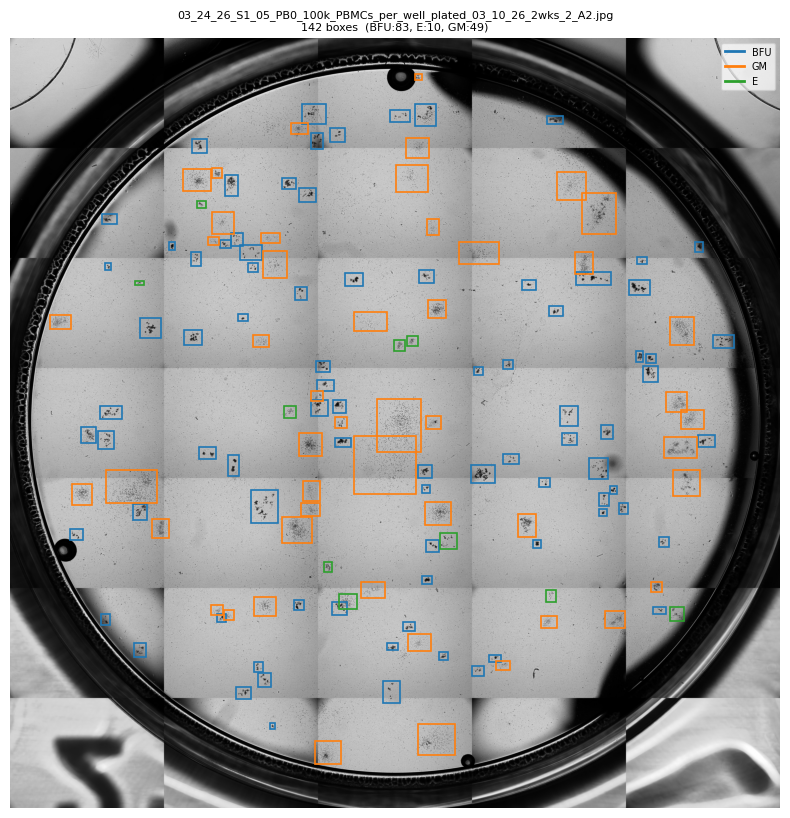

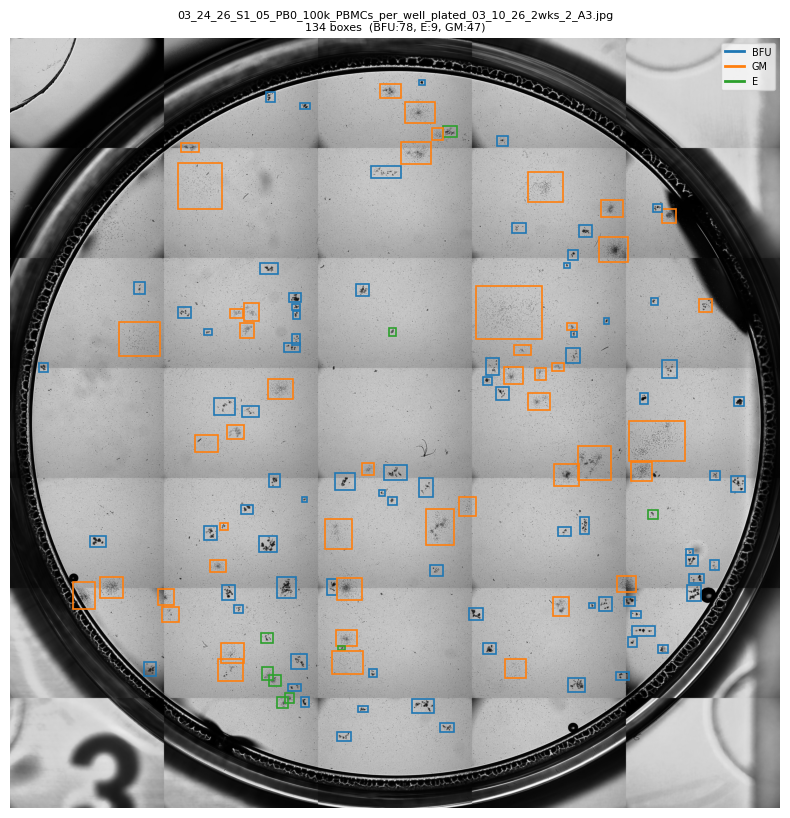

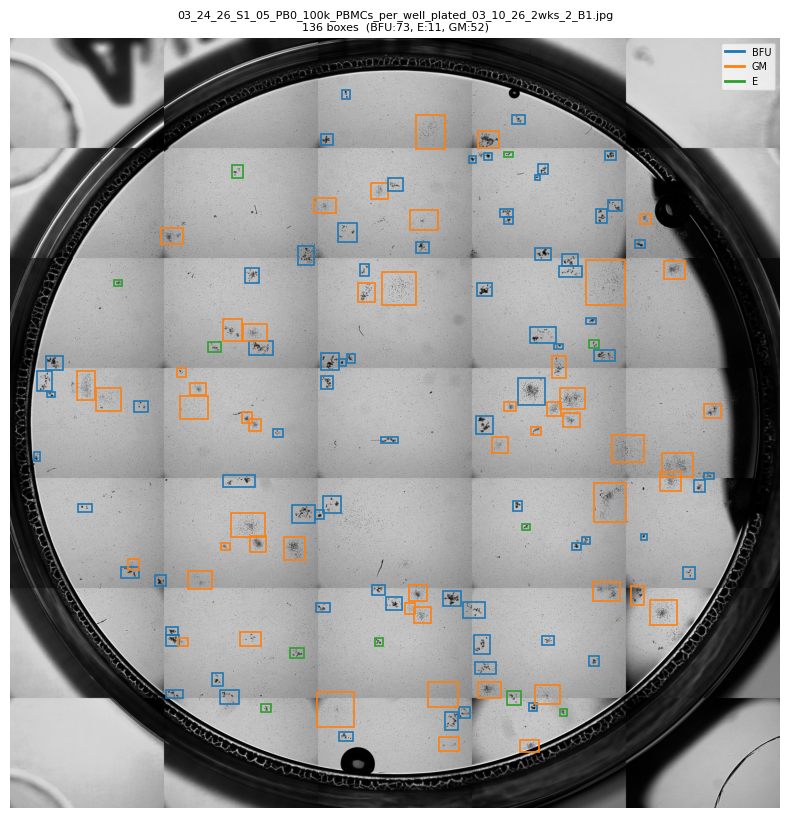

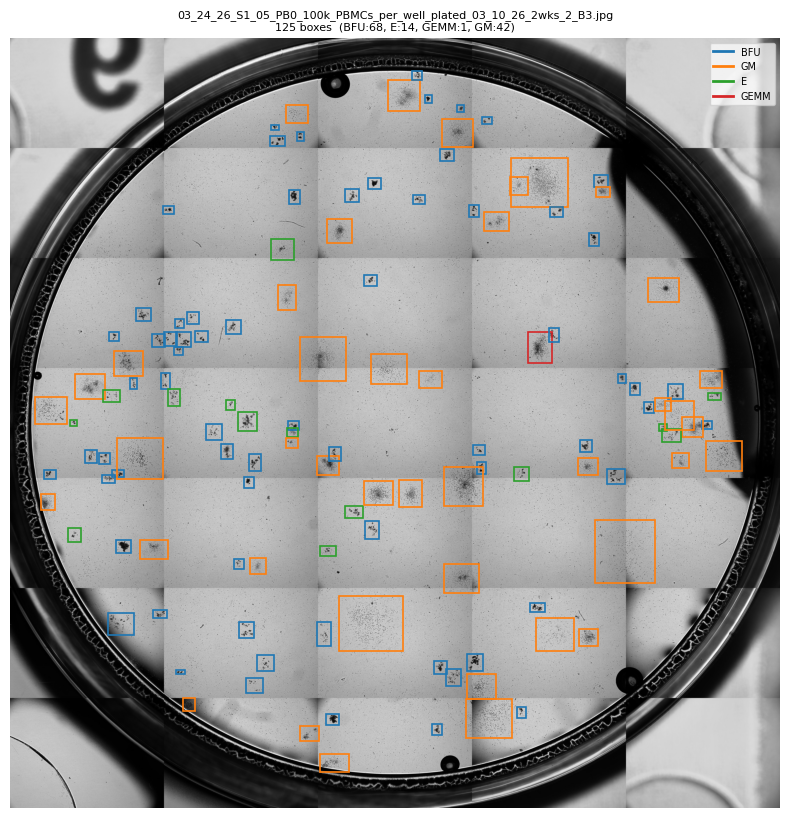

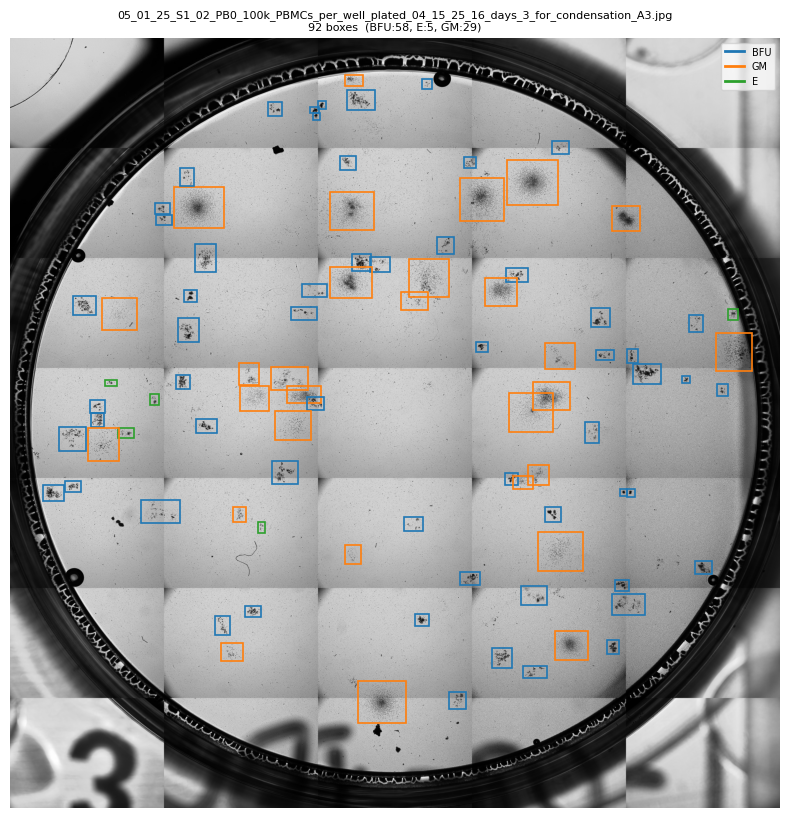

...

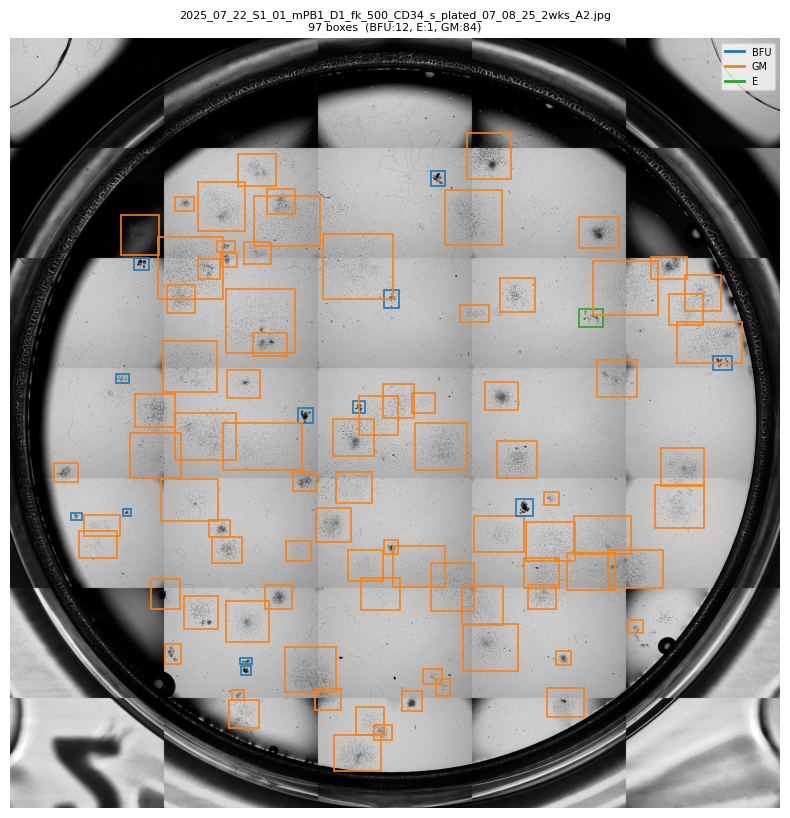

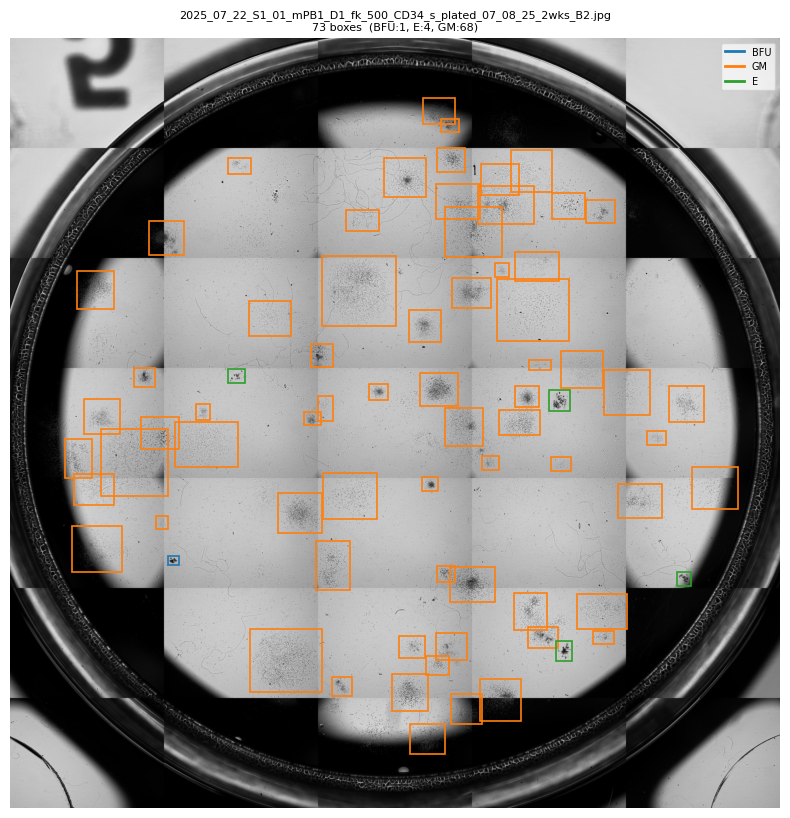

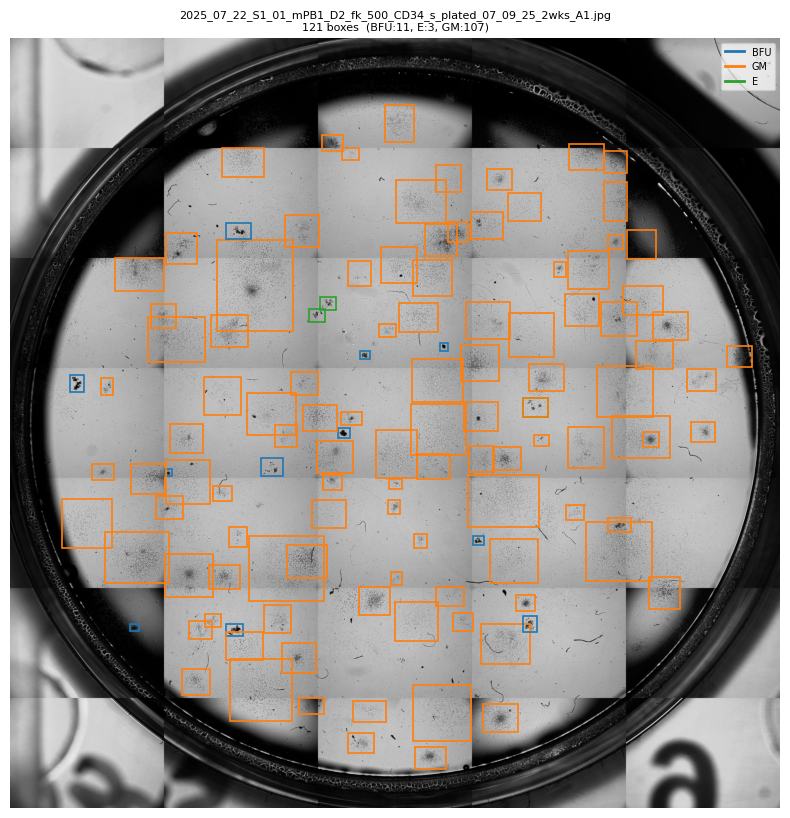

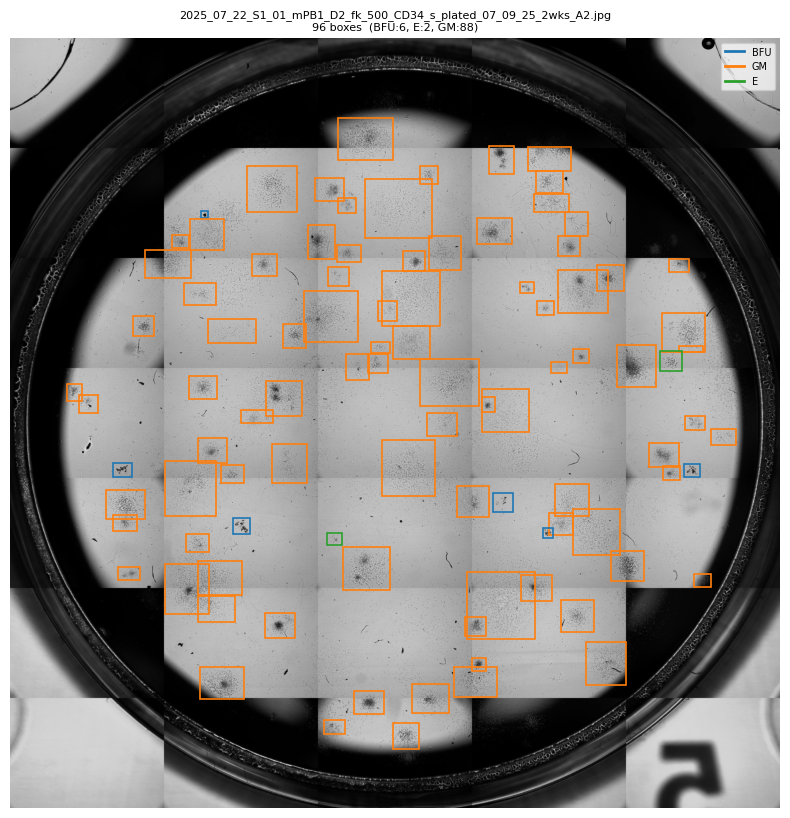

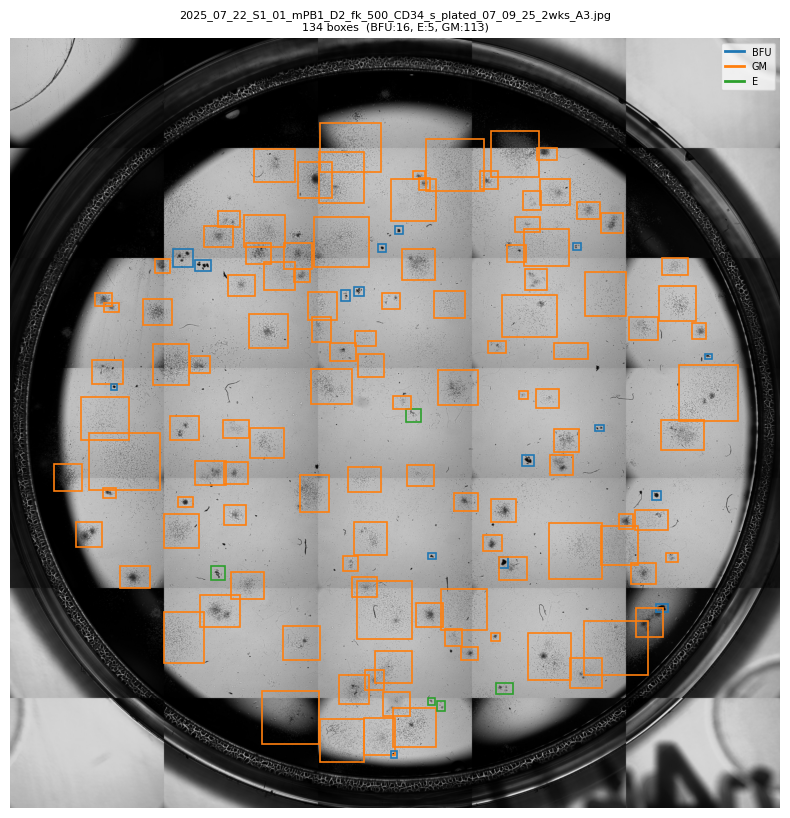

In [18]:
image_paths = sorted(p for p in Path(IMAGES_DIR).iterdir() if p.suffix.lower() in IMG_EXT)
if ONLY_LABELED:
    image_paths = [p for p in image_paths if read_yolo(label_for(p))]
if MAX_IMAGES:
    image_paths = image_paths[:MAX_IMAGES]

print(f"visualizing {len(image_paths)} image(s)")
for p in image_paths:
    visualize(p)